In [20]:
# Importing the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%pip install openpyxl

# Loading/reading the Excel dataset
df = pd.read_excel("Monthly_traffic_data_1992-current.xlsx")

Note: you may need to restart the kernel to use updated packages.


In [21]:
# Filtering the Excel dataset
df = pd.read_excel(
    "Monthly_traffic_data_1992-current.xlsx",
    header=[7, 8]
)

data = df[
    [
        ('Unnamed: 0_level_0', 'Year'),
        ('Unnamed: 1_level_0', 'Month'),
        ('Passengers', 'Total*')
    ]
].copy()

data.columns = ['Year', 'Month', 'Passengers']
data['Year'] = data['Year'].ffill()

months = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

data = data[data['Month'].isin(months)].copy()

data['Year'] = pd.to_numeric(data['Year'], errors='coerce')
data = data.dropna(subset=['Year'])
data['Year'] = data['Year'].astype(int)

data['Date'] = pd.to_datetime(
    data['Year'].astype(str) + ' ' + data['Month'],
    format='%Y %B'
)

data.head(15)

,Year,Month,Passengers,Date
0,1992,January,1149822.0,1992-01-01
1,1992,February,1086979.0,1992-02-01
2,1992,March,1276674.0,1992-03-01
3,1992,April,1522522.0,1992-04-01
4,1992,May,1742117.0,1992-05-01
5,1992,June,1737275.0,1992-06-01
6,1992,July,1979900.0,1992-07-01
7,1992,August,2061036.0,1992-08-01
8,1992,September,1867943.0,1992-09-01
9,1992,October,1707752.0,1992-10-01


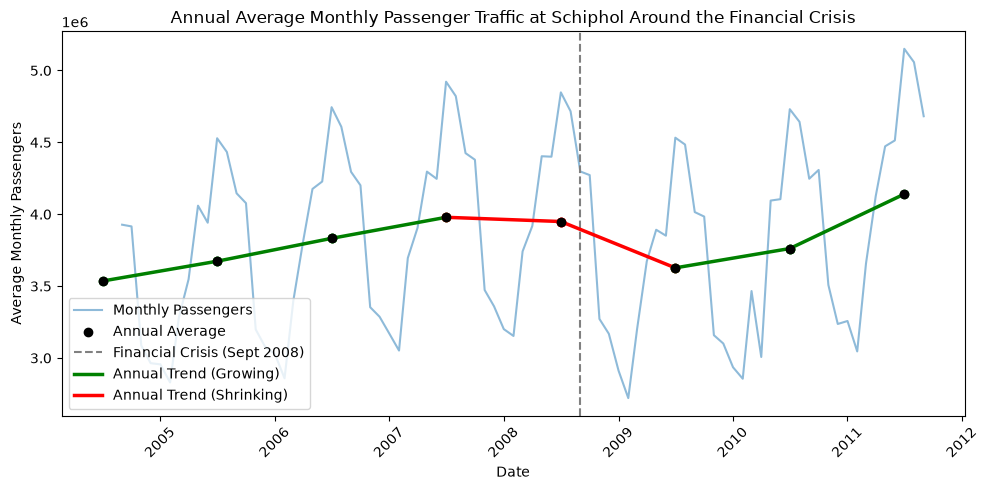

In [22]:
from matplotlib.lines import Line2D

# 1. Load and clean data
df = pd.read_excel('Monthly_traffic_data_1992-current.xlsx', header=8)
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
data = df[df['Month'].isin(months)].copy()
data['Year'] = data['Year'].ffill().astype(int)

month_map = {
    'January': '01', 'February': '02', 'March': '03', 'April': '04',
    'May': '05', 'June': '06', 'July': '07', 'August': '08',
    'September': '09', 'October': '10', 'November': '11', 'December': '12'
}
data['Month_Num'] = data['Month'].map(month_map)
data['Date'] = pd.to_datetime(data['Year'].astype(str) + '-' + data['Month_Num'] + '-01')
data['Passengers'] = data['Total*']

# 2. Filter for financial crisis range
event_financial = data[
    (data['Date'] >= '2004-09-01') &
    (data['Date'] <= '2011-09-01')
].copy()

# 3. Calculate annual average monthly passengers for each year
years = range(2004, 2012)
annual_pts = []
for y in years:
    yr_data = data[data['Year'] == y]
    avg_pass = yr_data['Passengers'].mean()
    # Place point in the middle of the year (July 1st)
    mid_date = pd.to_datetime(f"{y}-07-01")
    annual_pts.append({'Year': y, 'Date': mid_date, 'Passengers': avg_pass})

df_annual = pd.DataFrame(annual_pts)

# 4. Plotting
plt.figure(figsize=(10, 5))
plt.plot(event_financial['Date'], event_financial['Passengers'], label='Monthly Passengers', color='#1f77b4', alpha=0.5)

dates = df_annual['Date'].values
vals = df_annual['Passengers'].values

# Plot annual average points
plt.scatter(dates, vals, color='black', zorder=5, label='Annual Average')

# Draw segments between consecutive annual averages with green (growing) or red (shrinking)
for i in range(len(dates) - 1):
    x_seg = [dates[i], dates[i+1]]
    y_seg = [vals[i], vals[i+1]]
    color = 'green' if vals[i+1] > vals[i] else 'red'
    plt.plot(x_seg, y_seg, color=color, linestyle='-', marker='o', linewidth=2.5, zorder=4)

# Financial crisis marker
plt.axvline(
    pd.Timestamp('2008-09-01'),
    linestyle='--',
    color='gray',
    label='Financial Crisis (Sept 2008)'
)

# Custom legend items
custom_lines = [
    Line2D([0], [0], color='green', lw=2.5, label='Annual Trend (Growing)'),
    Line2D([0], [0], color='red', lw=2.5, label='Annual Trend (Shrinking)')
]
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles + custom_lines, loc='lower left')

plt.xlabel('Date')
plt.ylabel('Average Monthly Passengers')
plt.title('Annual Average Monthly Passenger Traffic at Schiphol Around the Financial Crisis')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

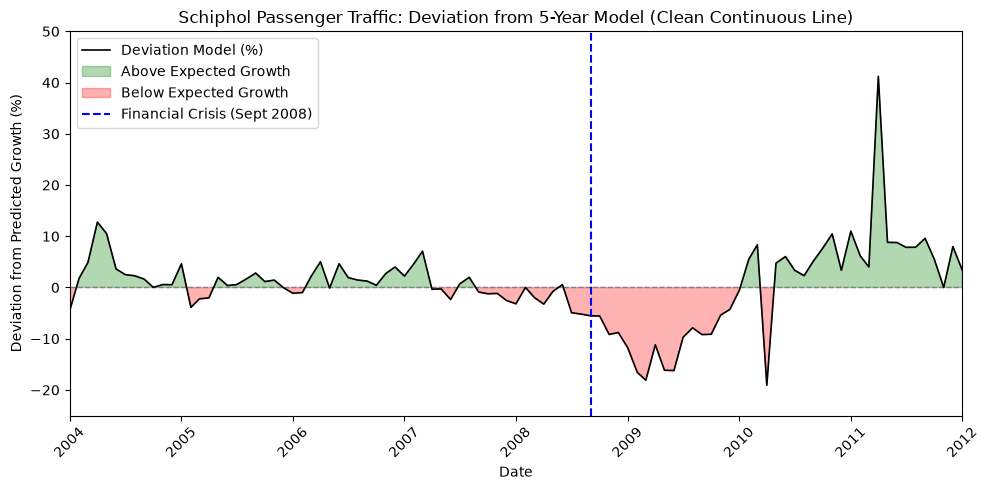

In [28]:
# Calculate month-over-month YoY growth across the entire historical series
data['YoY_Growth'] = data.groupby('Month_Num')['Passengers'].pct_change()

# For each month starting from 2004, predict expected volume using the preceding 5-year average growth rate
results = []
df_sorted = data.sort_values('Date').reset_index(drop=True)

for idx, row in df_sorted[df_sorted['Year'] >= 2004].iterrows():
    y = row['Year']
    m_num = row['Month_Num']
    actual = row['Passengers']
    
    train_start = y - 5
    train_end = y - 1
    
    train_data = df_sorted[(df_sorted['Year'] >= train_start) & (df_sorted['Year'] <= train_end)]
    m_train = train_data[train_data['Month_Num'] == m_num]
    avg_growth = m_train['YoY_Growth'].mean()
    
    prev_yr_row = df_sorted[(df_sorted['Year'] == y - 1) & (df_sorted['Month_Num'] == m_num)]
    if not prev_yr_row.empty:
        prev_actual = prev_yr_row['Passengers'].values[0]
        predicted = prev_actual * (1 + avg_growth)
        deviation = ((actual - predicted) / predicted) * 100
    else:
        deviation = np.nan
        
    results.append({
        'Date': row['Date'],
        'Deviation': deviation
    })

res_df = pd.DataFrame(results)
res_window = res_df[(res_df['Date'] >= '2004-01-01') & (res_df['Date'] <= '2012-01-01')].copy().reset_index(drop=True)

# Clean Plotting
plt.figure(figsize=(10, 5))
dates = res_window['Date'].values
devs = res_window['Deviation'].values

# Continuous line
plt.plot(dates, devs, color='black', linewidth=1.2, label='Deviation Model (%)', zorder=3)

# Shaded fills for performance zones
plt.fill_between(dates, devs, 0, where=(devs >= 0), color='green', alpha=0.3, interpolate=True, label='Above Expected Growth')
plt.fill_between(dates, devs, 0, where=(devs < 0), color='red', alpha=0.3, interpolate=True, label='Below Expected Growth')

plt.axhline(0, linestyle='--', color='gray', linewidth=1)
plt.axvline(
    pd.Timestamp('2008-09-01'),
    linestyle='--',
    color='blue',
    label='Financial Crisis (Sept 2008)',
    zorder=4
)

plt.xlim(pd.Timestamp('2004-01-01'), pd.Timestamp('2012-01-01'))
plt.ylim(-25, 50)

plt.xlabel('Date')
plt.ylabel('Deviation from Predicted Growth (%)')
plt.title('Schiphol Passenger Traffic: Deviation from 5-Year Model (Clean Continuous Line)')
plt.legend(loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

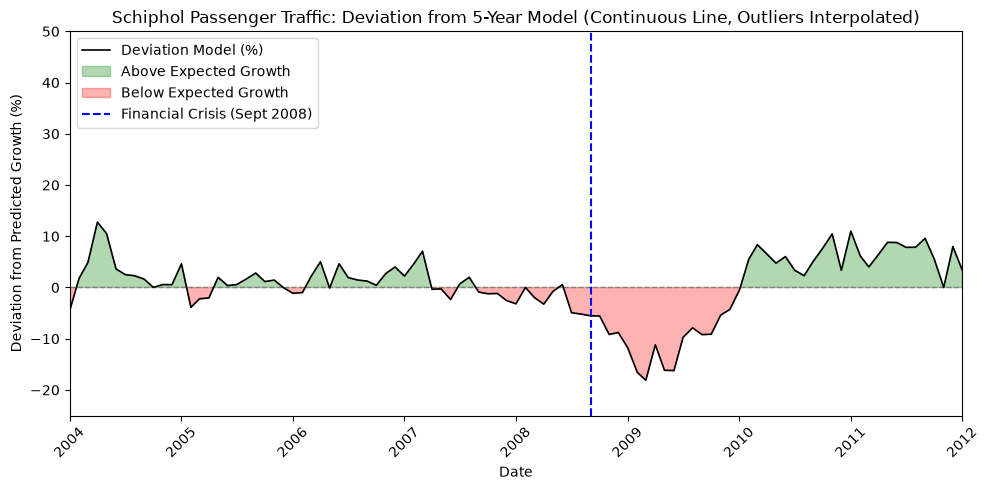

In [29]:
# Calculate month-over-month YoY growth across the entire historical series
data['YoY_Growth'] = data.groupby('Month_Num')['Passengers'].pct_change()

# For each month starting from 2004, predict expected volume using the preceding 5-year average growth rate
results = []
df_sorted = data.sort_values('Date').reset_index(drop=True)

for idx, row in df_sorted[df_sorted['Year'] >= 2004].iterrows():
    y = row['Year']
    m_num = row['Month_Num']
    actual = row['Passengers']
    
    train_start = y - 5
    train_end = y - 1
    
    train_data = df_sorted[(df_sorted['Year'] >= train_start) & (df_sorted['Year'] <= train_end)]
    m_train = train_data[train_data['Month_Num'] == m_num]
    avg_growth = m_train['YoY_Growth'].mean()
    
    prev_yr_row = df_sorted[(df_sorted['Year'] == y - 1) & (df_sorted['Month_Num'] == m_num)]
    if not prev_yr_row.empty:
        prev_actual = prev_yr_row['Passengers'].values[0]
        predicted = prev_actual * (1 + avg_growth)
        deviation = ((actual - predicted) / predicted) * 100
    else:
        deviation = np.nan
        
    # Mark April 2010 and April 2011 as NaN initially to remove the distortion
    if row['Date'] in [pd.Timestamp('2010-04-01'), pd.Timestamp('2011-04-01')]:
        deviation = np.nan
        
    results.append({
        'Date': row['Date'],
        'Deviation': deviation
    })

res_df = pd.DataFrame(results)
res_window = res_df[(res_df['Date'] >= '2004-01-01') & (res_df['Date'] <= '2012-01-01')].copy().reset_index(drop=True)

# Interpolate the missing outlier points so the line stays completely continuous with no blanks
res_window['Deviation'] = res_window['Deviation'].interpolate(method='linear')

# Clean Plotting
plt.figure(figsize=(10, 5))
dates = res_window['Date'].values
devs = res_window['Deviation'].values

# Continuous line
plt.plot(dates, devs, color='black', linewidth=1.2, label='Deviation Model (%)', zorder=3)

# Shaded fills for performance zones
plt.fill_between(dates, devs, 0, where=(devs >= 0), color='green', alpha=0.3, interpolate=True, label='Above Expected Growth')
plt.fill_between(dates, devs, 0, where=(devs < 0), color='red', alpha=0.3, interpolate=True, label='Below Expected Growth')

plt.axhline(0, linestyle='--', color='gray', linewidth=1)
plt.axvline(
    pd.Timestamp('2008-09-01'),
    linestyle='--',
    color='blue',
    label='Financial Crisis (Sept 2008)',
    zorder=4
)

plt.xlim(pd.Timestamp('2004-01-01'), pd.Timestamp('2012-01-01'))
plt.ylim(-25, 50)

plt.xlabel('Date')
plt.ylabel('Deviation from Predicted Growth (%)')
plt.title('Schiphol Passenger Traffic: Deviation from 5-Year Model (Continuous Line, Outliers Interpolated)')
plt.legend(loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

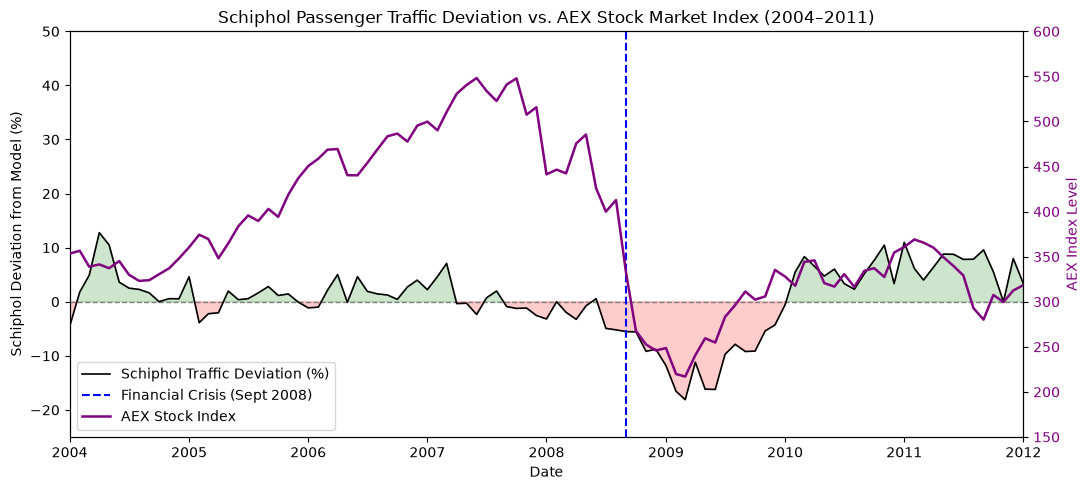

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Laad en schone Schiphol-data op
df = pd.read_excel('Monthly_traffic_data_1992-current.xlsx', header=8)
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
data = df[df['Month'].isin(months)].copy()
data['Year'] = data['Year'].ffill().astype(int)

month_map = {
    'January': '01', 'February': '02', 'March': '03', 'April': '04',
    'May': '05', 'June': '06', 'July': '07', 'August': '08',
    'September': '09', 'October': '10', 'November': '11', 'December': '12'
}
data['Month_Num'] = data['Month'].map(month_map)
data['Date'] = pd.to_datetime(data['Year'].astype(str) + '-' + data['Month_Num'] + '-01')
data['Passengers'] = data['Total*']

# 2. Bereken Schiphol 5-jaars modelafwijking
data['YoY_Growth'] = data.groupby('Month_Num')['Passengers'].pct_change()

results = []
df_sorted = data.sort_values('Date').reset_index(drop=True)

for idx, row in df_sorted[df_sorted['Year'] >= 2004].iterrows():
    y = row['Year']
    m_num = row['Month_Num']
    actual = row['Passengers']
    
    train_start = y - 5
    train_end = y - 1
    
    train_data = df_sorted[(df_sorted['Year'] >= train_start) & (df_sorted['Year'] <= train_end)]
    m_train = train_data[train_data['Month_Num'] == m_num]
    avg_growth = m_train['YoY_Growth'].mean()
    
    prev_yr_row = df_sorted[(df_sorted['Year'] == y - 1) & (df_sorted['Month_Num'] == m_num)]
    if not prev_yr_row.empty:
        prev_actual = prev_yr_row['Passengers'].values[0]
        predicted = prev_actual * (1 + avg_growth)
        deviation = ((actual - predicted) / predicted) * 100
    else:
        deviation = np.nan
        
    # Uitschieters van april 2010 en april 2011 op NaN zetten om te interpoleren
    if row['Date'] in [pd.Timestamp('2010-04-01'), pd.Timestamp('2011-04-01')]:
        deviation = np.nan
        
    results.append({
        'Date': row['Date'],
        'Deviation': deviation
    })

res_df = pd.DataFrame(results)
res_window = res_df[(res_df['Date'] >= '2004-01-01') & (res_df['Date'] <= '2012-01-01')].copy().reset_index(drop=True)
res_window['Deviation'] = res_window['Deviation'].interpolate(method='linear')

# 3. Laad en verwerk de AEX-dataset uit het geüploade CSV-bestand
aex_df = pd.read_csv('AEX Historische Data.csv')
aex_df['Date'] = pd.to_datetime(aex_df['Datum'], format='%d-%m-%Y')
aex_df['AEX'] = aex_df['Laatste'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
aex_clean = aex_df[['Date', 'AEX']].sort_values('Date').reset_index(drop=True)

# Samenvoegen met de Schiphol-vensterdata op datum
merged_df = pd.merge(res_window, aex_clean, on='Date', how='inner')

# 4. Dubbele-as visualisatie
fig, ax1 = plt.subplots(figsize=(11, 5))

dates = merged_df['Date'].values
devs = merged_df['Deviation'].values
aex_vals = merged_df['AEX'].values

# Primaire as (Links): Schiphol Passagiersafwijking (%)
ax1.plot(dates, devs, color='black', linewidth=1.2, label='Schiphol Traffic Deviation (%)', zorder=3)
ax1.fill_between(dates, devs, 0, where=(devs >= 0), color='green', alpha=0.2, interpolate=True)
ax1.fill_between(dates, devs, 0, where=(devs < 0), color='red', alpha=0.2, interpolate=True)
ax1.axhline(0, linestyle='--', color='gray', linewidth=1)
ax1.axvline(pd.Timestamp('2008-09-01'), linestyle='--', color='blue', label='Financial Crisis (Sept 2008)', zorder=4)

ax1.set_xlabel('Date')
ax1.set_ylabel('Schiphol Deviation from Model (%)', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_ylim(-25, 50)

# Secundaire as (Rechts): AEX Beursindex (paarse lijn)
ax2 = ax1.twinx()
ax2.plot(dates, aex_vals, color='purple', linewidth=1.8, linestyle='-', label='AEX Stock Index', zorder=5)
ax2.set_ylabel('AEX Index Level', color='purple')
ax2.tick_params(axis='y', labelcolor='purple')
ax2.set_ylim(150, 600)

ax1.set_xlim(pd.Timestamp('2004-01-01'), pd.Timestamp('2012-01-01'))
plt.title('Schiphol Passenger Traffic Deviation vs. AEX Stock Market Index (2004–2011)')

# Legenda combineren
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower left')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()